# T14. Saldo neto orígenes − destinos por celda, franja y día

**Objetivo.** Ver dónde se acumulan o se vacían los patinetes y cuándo: el saldo O − D de cada celda H3 de resolución 8 en el periodo, por franja horaria y día a día.

**Valor para el proyecto.** Dice si hará falta rebalanceo y de qué orden de magnitud al día, qué zonas piden más anclajes (receptoras) y cuáles más stock inicial (emisoras), y en qué franjas se produce el desequilibrio. También contrasta el saldo con las recolocaciones del operador de T11.

Las cifras salen del periodo de ajuste (1–21/02) con los viajes elegibles; el contraste con T11 usa, como T11, todos los viajes del mes. Las salidas se cuentan por la hora de `tsO` y las llegadas por la de `tsD`.

In [1]:
import h3
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import patheffects
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.dates import DateFormatter
from matplotlib.ticker import FormatStrFormatter, FuncFormatter, MaxNLocator
from scipy.stats import spearmanr

from comun.config import cargar_config, carpeta_tablas
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.geo import haversine_m
from comun.web import exportar

TEMA, FASE = "exploracion", "fase0"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()
RESOLUCIONES = CFG["exploracion"]["resoluciones_h3"]
FRANJAS = CFG["exploracion"]["franjas_horarias"]
NOMBRES_FRANJA = {"madrugada": "Madrugada", "punta_manana": "Punta de mañana", "mediodia": "Mediodía",
                  "punta_tarde": "Punta de tarde", "noche": "Noche"}

PARAMETROS = {
    "res_mapas": CFG["movilidad"]["resolucion_mapas"],
    # Mínimo de orígenes + destinos para que una celda cuente. Si una celda estuviera
    # equilibrada, cada extremo sería origen o destino con p = 0,5 y la desviación típica
    # de saldo_rel sería 1/sqrt(n): con n = 30, 0,18. Por debajo de 30 extremos el ruido
    # domina cualquier desequilibrio moderado.
    "saldo_min_extremos": 30,
    # Número de celdas con mayor saldo absoluto en la figura del saldo acumulado.
    "saldo_top_celdas": 10,
}
TITULO_AJUSTE = "periodo de ajuste (1–21/02/2021)"

# Rampa secuencial de un solo tono (azul) y color para celdas sin dato.
CMAP_SECUENCIAL = LinearSegmentedColormap.from_list(
    "azules", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
CMAP_SECUENCIAL.set_bad("#e4e3df")
COLOR_TEXTO = "#3d3c39"
HALO = [patheffects.withStroke(linewidth=2.2, foreground="white")]
# Puntos de referencia para orientar los mapas (lat, lon aproximadas).
REFERENCIAS = {"Termini": (41.9009, 12.5019), "Coliseo": (41.8903, 12.4922), "San Pedro": (41.9022, 12.4536)}


def guardar_tabla(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", index=False, lineterminator="\n")


def celda(lat, lon, res):
    """Celda H3 de cada punto."""
    return pd.Series([h3.latlng_to_cell(a, b, res) for a, b in zip(lat, lon)], index=lat.index, dtype="string")


def centros(celdas):
    """Latitud y longitud del centro de cada celda."""
    coords = np.array([h3.cell_to_latlng(c) for c in celdas], dtype=float).reshape(-1, 2)
    return coords[:, 0], coords[:, 1]


def poligonos(celdas):
    """Contorno (lon, lat) de cada celda."""
    return [np.array(h3.cell_to_boundary(c))[:, ::-1] for c in celdas]


def contornos_web(celdas):
    """Contornos para la web: lista de [lon, lat] con 5 decimales por celda."""
    return [np.round(p, 5).tolist() for p in poligonos(celdas)]


def dibujar_celdas(eje, celdas, valores, cmap, norm, borde="white"):
    pc = PolyCollection(poligonos(celdas), array=np.asarray(valores, dtype=float), cmap=cmap,
                        norm=norm, edgecolors=borde, linewidths=0.3)
    eje.add_collection(pc)
    return pc


def extension(celdas, margen=0.004):
    puntos = np.vstack(poligonos(celdas))
    return (puntos[:, 0].min() - margen, puntos[:, 0].max() + margen,
            puntos[:, 1].min() - margen, puntos[:, 1].max() + margen)


def preparar_mapa(eje, ext, referencias=True, ejes=True, escala=True):
    """Límites, proporción local, puntos de referencia y barra de escala de 1 km."""
    lon0, lon1, lat0, lat1 = ext
    eje.set_xlim(lon0, lon1)
    eje.set_ylim(lat0, lat1)
    eje.set_aspect(1 / np.cos(np.radians((lat0 + lat1) / 2)))
    eje.grid(False)
    eje.tick_params(labelsize=8)
    eje.xaxis.set_major_locator(MaxNLocator(3))
    eje.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    eje.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    if ejes:
        eje.set_xlabel("Longitud (°)")
        eje.set_ylabel("Latitud (°)")
    else:
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in ("left", "bottom"):
            eje.spines[lado].set_visible(False)
    if referencias:
        for nombre, (lat, lon) in REFERENCIAS.items():
            if lon0 < lon < lon1 and lat0 < lat < lat1:
                eje.plot(lon, lat, marker="o", ms=3.5, mfc="white", mec="black", mew=0.8, zorder=5)
                eje.annotate(nombre, (lon, lat), xytext=(3, 3), textcoords="offset points",
                             fontsize=8, color="black", zorder=5, path_effects=HALO)
    if not escala:
        return
    # Barra de escala de 1 km en la esquina inferior izquierda.
    lat_b = lat0 + 0.05 * (lat1 - lat0)
    grados_km = 1000 / haversine_m(lat_b, 0.0, lat_b, 1.0)
    lon_b = lon0 + 0.06 * (lon1 - lon0)
    eje.plot([lon_b, lon_b + grados_km], [lat_b, lat_b], color="black", lw=2, solid_capstyle="butt")
    eje.annotate("1 km", (lon_b + grados_km / 2, lat_b), xytext=(0, 3), textcoords="offset points",
                 ha="center", fontsize=8, path_effects=HALO)


def barra_log(fig, pc, eje, etiqueta):
    """Barra de color con números enteros en lugar de potencias de 10."""
    barra = fig.colorbar(pc, ax=eje, shrink=0.8, pad=0.02)
    barra.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    barra.set_label(etiqueta)
    return barra


def tabla_indicadores(resumen):
    """Tabla indicador/valor que conserva los enteros como enteros en el CSV."""
    return pd.DataFrame({"indicador": list(resumen), "valor": pd.Series(list(resumen.values()), dtype=object)})

# Escala divergente: receptoras (D > O) en azul, emisoras (O > D) en rojo, centro gris.
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list(
    "saldo", ["#0d366b", "#2a78d6", "#9ec5f4", "#f0efec", "#f3b1a9", "#e34948", "#8f1d1d"])
CMAP_DIVERGENTE.set_bad("#d5d4cf")
COLOR_EMISORA, COLOR_RECEPTORA, GRIS_REF = "#e34948", "#2a78d6", "#8a8984"


def franja(hora):
    """Nombre de la franja horaria de cada hora."""
    etiqueta = pd.Series(pd.NA, index=hora.index, dtype="string")
    for nombre, (inicio, fin) in FRANJAS.items():
        etiqueta[(hora >= inicio) & (hora < fin)] = nombre
    assert etiqueta.notna().all()
    return etiqueta


def dias_periodo(nombre):
    inicio, fin = CFG["datos"]["periodos"][nombre]
    return pd.Index(pd.date_range(inicio, fin, freq="D").strftime("%Y-%m-%d"), dtype="string")


def extremos(viajes, res):
    """Salidas (por tsO) y llegadas (por tsD) con su celda, día y franja."""
    o = pd.DataFrame({"h3": celda(viajes["latO"], viajes["lonO"], res),
                      "fecha": viajes["tsO"].dt.strftime("%Y-%m-%d").astype("string"),
                      "franja": franja(viajes["tsO"].dt.hour)})
    d = pd.DataFrame({"h3": celda(viajes["latD"], viajes["lonD"], res),
                      "fecha": viajes["tsD"].dt.strftime("%Y-%m-%d").astype("string"),
                      "franja": franja(viajes["tsD"].dt.hour)})
    return o, d


def saldo(o, d, claves):
    """Orígenes, destinos, saldo O − D y saldo relativo agrupados por `claves`."""
    t = pd.concat([o.groupby(claves).size().rename("origenes"),
                   d.groupby(claves).size().rename("destinos")], axis=1).fillna(0).astype("int64")
    t["extremos"] = t["origenes"] + t["destinos"]
    t["saldo"] = t["origenes"] - t["destinos"]
    t["saldo_rel"] = (t["saldo"] / t["extremos"]).round(4)
    t["incluida"] = t["extremos"] >= PARAMETROS["saldo_min_extremos"]
    return t.reset_index()


def mapa_saldo(eje, t, columna, norm, ext, **kw):
    """Celdas incluidas con escala divergente y el resto en gris."""
    pc = dibujar_celdas(eje, t["h3"], t[columna].where(t["incluida"], np.nan), CMAP_DIVERGENTE, norm)
    preparar_mapa(eje, ext, **kw)
    return pc


ajuste = cargar_viajes(periodo="ajuste")
todos = cargar_viajes(solo_elegibles=False)
DIAS = dias_periodo("ajuste")
N_DIAS = len(DIAS)
o, d = extremos(ajuste, PARAMETROS["res_mapas"])
print(f"{len(ajuste)} viajes elegibles en los {N_DIAS} días del ajuste")

16756 viajes elegibles en los 21 días del ajuste


## 1. Saldo por celda

**Qué queremos ver.** Orígenes, destinos, saldo `O − D` y saldo relativo `(O − D)/(O + D)` de cada celda, con un mapa de escala divergente centrada en 0.

**Por qué importa.** Una celda emisora (más salidas que llegadas) se vacía y pide stock inicial; una receptora se llena y pide anclajes libres. Solo cuentan las celdas con al menos 30 extremos, para que el ruido no domine.

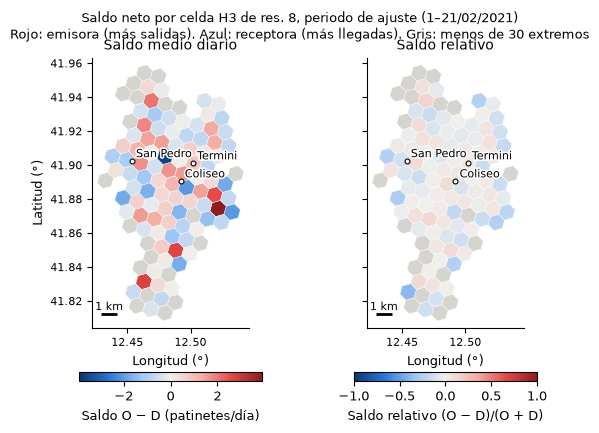

,valor
viajes,16756.00
dias,21.00
llegadas_fuera_del_periodo,1.00
celdas_res8,111.00
celdas_incluidas,90.00
pct_extremos_en_celdas_incluidas,99.34
celdas_emisoras,42.00
celdas_receptoras,45.00
celdas_equilibradas,3.00
celdas_desequilibrio_signif_2sigma,14.00


,h3,origenes,destinos,extremos,saldo,saldo_rel,incluida,saldo_dia,signif_2sigma,tipo,lat,lon
0,881e805089fffff,842,760,1602,82,0.0512,True,3.905,True,emisora,41.874359,12.521776
1,881e805189fffff,281,223,504,58,0.1151,True,2.762,True,emisora,41.831448,12.463147
2,881e8051dbfffff,290,233,523,57,0.1090,True,2.714,True,emisora,41.849842,12.488265
3,881e8050c3fffff,664,610,1274,54,0.0424,True,2.571,False,emisora,41.882557,12.519013
4,881e805213fffff,172,129,301,43,0.1429,True,2.048,True,emisora,41.937926,12.468983


,h3,origenes,destinos,extremos,saldo,saldo_rel,incluida,saldo_dia,signif_2sigma,tipo,lat,lon
106,881e805001fffff,49,86,135,-37,-0.2741,True,-1.762,True,receptora,41.880631,12.446547
107,881e8050ddfffff,104,141,245,-37,-0.1510,True,-1.762,True,receptora,41.888685,12.527395
108,881e80508bfffff,83,126,209,-43,-0.2057,True,-2.048,True,receptora,41.872287,12.532918
109,881e8050cdfffff,196,239,435,-43,-0.0989,True,-2.048,True,receptora,41.886696,12.496727
110,881e8052adfffff,496,572,1068,-76,-0.0712,True,-3.619,True,receptora,41.905154,12.480052


In [2]:
total = saldo(o, d, ["h3"])
total["saldo_dia"] = (total["saldo"] / N_DIAS).round(3)
# Desequilibrio mayor que dos desviaciones típicas del caso equilibrado.
total["signif_2sigma"] = total["saldo_rel"].abs() > 2 / np.sqrt(total["extremos"])
total["tipo"] = np.select([~total["incluida"], total["saldo"] > 0, total["saldo"] < 0],
                          ["poco_uso", "emisora", "receptora"], "equilibrada")
total["lat"], total["lon"] = centros(total["h3"])
total[["lat", "lon"]] = total[["lat", "lon"]].round(6)
total = total.sort_values(["saldo", "h3"], ascending=[False, True], ignore_index=True)
guardar_tabla(total, "T14_saldo_celdas")

EXT = extension(total["h3"])
fig, ejes = plt.subplots(1, 2, figsize=(6.5, 4.8), sharey=True)
lim = total.loc[total["incluida"], "saldo_dia"].abs().max()
pc = mapa_saldo(ejes[0], total, "saldo_dia", Normalize(-lim, lim), EXT)
fig.colorbar(pc, ax=ejes[0], shrink=0.8, pad=0.12, location="bottom").set_label("Saldo O − D (patinetes/día)")
ejes[0].set_title("Saldo medio diario")
pc = mapa_saldo(ejes[1], total, "saldo_rel", Normalize(-1, 1), EXT)
fig.colorbar(pc, ax=ejes[1], shrink=0.8, pad=0.12, location="bottom").set_label("Saldo relativo (O − D)/(O + D)")
ejes[1].set_title("Saldo relativo")
ejes[1].set_ylabel("")
fig.suptitle(f"Saldo neto por celda H3 de res. {PARAMETROS['res_mapas']}, {TITULO_AJUSTE}\n"
             "Rojo: emisora (más salidas). Azul: receptora (más llegadas). "
             f"Gris: menos de {PARAMETROS['saldo_min_extremos']} extremos", fontsize=9)
guardar_figura(fig, TEMA, "T14_saldo")

inc = total[total["incluida"]]
indicadores = {
    "viajes": len(ajuste),
    "dias": N_DIAS,
    "llegadas_fuera_del_periodo": int((~d["fecha"].isin(DIAS)).sum()),
    "celdas_res8": len(total),
    "celdas_incluidas": len(inc),
    "pct_extremos_en_celdas_incluidas": round(100 * inc["extremos"].sum() / total["extremos"].sum(), 2),
    "celdas_emisoras": int((inc["saldo"] > 0).sum()),
    "celdas_receptoras": int((inc["saldo"] < 0).sum()),
    "celdas_equilibradas": int((inc["saldo"] == 0).sum()),
    "celdas_desequilibrio_signif_2sigma": int(inc["signif_2sigma"].sum()),
}
exportar(FASE, "t14_saldo", {
    "res": PARAMETROS["res_mapas"], "min_extremos": PARAMETROS["saldo_min_extremos"], "referencias": REFERENCIAS,
    "celdas": [{"h3": c, "origenes": int(oo), "destinos": int(dd), "saldo_dia": float(s), "saldo_rel": float(r),
                "incluida": bool(i), "contorno": q}
               for c, oo, dd, s, r, i, q in zip(total["h3"], total["origenes"], total["destinos"], total["saldo_dia"],
                                                total["saldo_rel"], total["incluida"], contornos_web(total["h3"]))],
})
display(pd.Series(indicadores).to_frame("valor"), total.head(5), total.tail(5))

**Conclusiones.**

- Cuentan 90 de las 111 celdas, con el 99,34 % de los extremos: 42 emisoras, 45 receptoras y 3 equilibradas. En 14 el desequilibrio supera dos desviaciones típicas del caso equilibrado.
- La principal emisora (`881e805089fffff`, al sureste del Coliseo) pierde 3,9 patinetes al día y la principal receptora (`881e8052adfffff`, entre San Pedro y Termini) gana 3,6. Hay varias emisoras en el sur.

## 2. Saldo por franja horaria

**Qué queremos ver.** El mismo mapa en cada franja horaria de T12, con la misma escala, y cuántos patinetes desplaza el flujo neto en cada franja.

**Por qué importa.** El saldo del día puede esconder movimientos que se compensan entre la mañana y la tarde. El simulador y el rebalanceo tienen que saber en qué franjas se produce el desequilibrio.

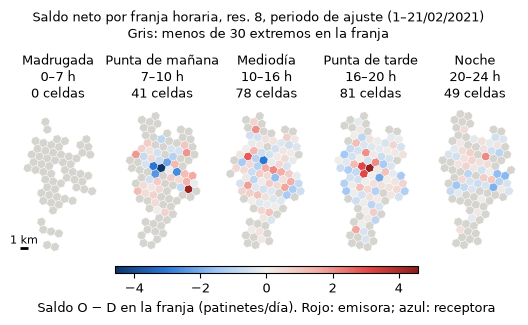

,franja,inicio_h,fin_h,salidas_dia,desplazamiento_estructural_patinetes_dia,desplazamiento_diario_medio_patinetes_dia,desplazamiento_estructural_patinetes_hora,pct_salidas_desplazadas_estructural
0,madrugada,0,7,7.2,4.1,5.4,0.6,56.6
1,punta_manana,7,10,91.8,29.8,43.1,9.9,32.4
2,mediodia,10,16,285.6,28.3,66.7,4.7,9.9
3,punta_tarde,16,20,315.2,29.1,71.8,7.3,9.2
4,noche,20,24,98.0,19.2,35.0,4.8,19.6


In [3]:
por_franja = saldo(o, d, ["h3", "franja"])
por_franja["saldo_dia"] = (por_franja["saldo"] / N_DIAS).round(3)
por_franja["_orden"] = por_franja["franja"].map({nombre: i for i, nombre in enumerate(FRANJAS)})
por_franja = (por_franja.sort_values(["_orden", "saldo", "h3"], ascending=[True, False, True], ignore_index=True)
              .drop(columns="_orden"))
guardar_tabla(por_franja, "T14_saldo_franjas")

lim = por_franja.loc[por_franja["incluida"], "saldo_dia"].abs().max()
norm = Normalize(-lim, lim)
fig, ejes = plt.subplots(1, len(FRANJAS), figsize=(6.5, 3.4))
for i, (eje, (nombre, (inicio, fin))) in enumerate(zip(ejes, FRANJAS.items())):
    sub = por_franja[por_franja["franja"] == nombre]
    pc = mapa_saldo(eje, sub, "saldo_dia", norm, EXT, ejes=False, referencias=False, escala=(i == 0))
    eje.set_title(f"{NOMBRES_FRANJA.get(nombre, nombre)}\n{inicio}–{fin} h\n{int(sub['incluida'].sum())} celdas",
                  fontsize=9)
barra = fig.colorbar(pc, ax=ejes, orientation="horizontal", shrink=0.6, pad=0.04, aspect=40)
barra.set_label("Saldo O − D en la franja (patinetes/día). Rojo: emisora; azul: receptora")
fig.suptitle(f"Saldo neto por franja horaria, res. {PARAMETROS['res_mapas']}, {TITULO_AJUSTE}\n"
             f"Gris: menos de {PARAMETROS['saldo_min_extremos']} extremos en la franja", fontsize=9)
guardar_figura(fig, TEMA, "T14_saldo_franjas")

# Desequilibrio por franja: patinetes que el flujo neto desplaza entre celdas.
por_dia = saldo(o, d, ["h3", "franja", "fecha"])
filas = []
for nombre, (inicio, fin) in FRANJAS.items():
    estructural = por_franja.loc[por_franja["franja"] == nombre, "saldo"].abs().sum() / 2 / N_DIAS
    diario = (por_dia[por_dia["franja"] == nombre].groupby("fecha")["saldo"].apply(lambda s: s.abs().sum() / 2)
              .reindex(DIAS, fill_value=0).mean())
    salidas = int(por_franja.loc[por_franja["franja"] == nombre, "origenes"].sum())
    filas.append({"franja": nombre, "inicio_h": inicio, "fin_h": fin,
                  "salidas_dia": round(salidas / N_DIAS, 1),
                  "desplazamiento_estructural_patinetes_dia": round(estructural, 1),
                  "desplazamiento_diario_medio_patinetes_dia": round(diario, 1),
                  "desplazamiento_estructural_patinetes_hora": round(estructural / (fin - inicio), 1),
                  "pct_salidas_desplazadas_estructural": round(100 * estructural * N_DIAS / salidas, 1)})
desequilibrio = pd.DataFrame(filas)
guardar_tabla(desequilibrio, "T14_desequilibrio_franjas")

exportar(FASE, "t14_franjas", {
    "franjas": [{"franja": nombre, "inicio_h": inicio, "fin_h": fin,
                 "celdas": por_franja.loc[por_franja["franja"] == nombre,
                                          ["h3", "origenes", "destinos", "saldo_dia", "incluida"]]}
                for nombre, (inicio, fin) in FRANJAS.items()],
    "desequilibrio": desequilibrio,
})
display(desequilibrio)

**Conclusiones.**

- En la punta de mañana el flujo neto desplaza 29,8 patinetes al día, el 32,4 % de sus salidas. Mediodía y punta de tarde desplazan casi lo mismo (28,3 y 29,1), pero es solo el 9,9 % y el 9,2 % de sus salidas.
- El centro recibe patinetes por la mañana y los devuelve por la tarde: el saldo diario esconde esa inversión, así que el simulador debe trabajar por franjas o en continuo.

## 3. Persistencia día a día

**Qué queremos ver.** El saldo diario de cada celda, la fracción de días en que tiene el mismo signo que en el periodo y el saldo acumulado de las 10 celdas con mayor saldo absoluto.

**Por qué importa.** Si el acumulado crece sin volver a cero, la acumulación es estructural: los patinetes no vuelven solos y hará falta rebalanceo.

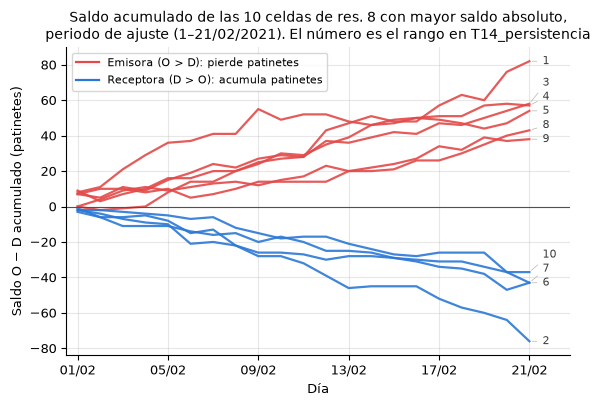

,rango_abs_saldo,h3,origenes,destinos,saldo,saldo_dia,tipo,signif_2sigma,dias_mismo_signo,dias_signo_contrario,dias_saldo_cero,dias_acumulado_mismo_signo,pct_dias_mismo_signo,pct_dias_acumulado_mismo_signo
0,1,881e805089fffff,842,760,82,3.905,emisora,True,14,6,1,21,66.7,100.0
1,2,881e8052adfffff,496,572,-76,-3.619,receptora,True,14,3,4,21,66.7,100.0
2,3,881e805189fffff,281,223,58,2.762,emisora,True,15,4,2,17,71.4,81.0
3,4,881e8051dbfffff,290,233,57,2.714,emisora,True,15,3,3,21,71.4,100.0
4,5,881e8050c3fffff,664,610,54,2.571,emisora,False,13,6,2,21,61.9,100.0
5,6,881e80508bfffff,83,126,-43,-2.048,receptora,True,14,3,4,21,66.7,100.0
6,7,881e8050cdfffff,196,239,-43,-2.048,receptora,True,15,3,3,21,71.4,100.0
7,8,881e805213fffff,172,129,43,2.048,emisora,True,15,3,3,20,71.4,95.2
8,9,881e8052edfffff,208,170,38,1.810,emisora,False,13,4,4,21,61.9,100.0
9,10,881e805001fffff,49,86,-37,-1.762,receptora,True,15,2,4,21,71.4,100.0


In [4]:
incluidas = total.loc[total["incluida"], "h3"]
diario = saldo(o[o["h3"].isin(incluidas)], d[d["h3"].isin(incluidas)], ["h3", "fecha"])
rejilla = pd.MultiIndex.from_product([incluidas.sort_values(), DIAS], names=["h3", "fecha"])
diario = (diario.set_index(["h3", "fecha"])[["origenes", "destinos", "saldo"]]
          .reindex(rejilla, fill_value=0).reset_index())
diario["saldo_acumulado"] = diario.groupby("h3")["saldo"].cumsum()
guardar_tabla(diario, "T14_saldo_diario")

signo_total = np.sign(total.set_index("h3")["saldo"])
s = diario.assign(signo=np.sign(diario["saldo"]), signo_acum=np.sign(diario["saldo_acumulado"]),
                  signo_total=diario["h3"].map(signo_total))
s["mismo"] = s["signo"] == s["signo_total"]
s["contrario"] = s["signo"] == -s["signo_total"]
s["cero"] = s["signo"] == 0
s["acum_mismo"] = s["signo_acum"] == s["signo_total"]
pers = s.groupby("h3")[["mismo", "contrario", "cero", "acum_mismo"]].sum().astype("int64")
pers.columns = ["dias_mismo_signo", "dias_signo_contrario", "dias_saldo_cero", "dias_acumulado_mismo_signo"]
pers["pct_dias_mismo_signo"] = (100 * pers["dias_mismo_signo"] / N_DIAS).round(1)
pers["pct_dias_acumulado_mismo_signo"] = (100 * pers["dias_acumulado_mismo_signo"] / N_DIAS).round(1)
pers = total.set_index("h3")[["origenes", "destinos", "saldo", "saldo_dia", "tipo", "signif_2sigma",
                              "lat", "lon"]].join(pers, how="inner").reset_index()
pers["_abs"] = pers["saldo"].abs()
pers = pers.sort_values(["_abs", "h3"], ascending=[False, True], ignore_index=True).drop(columns="_abs")
pers.insert(0, "rango_abs_saldo", np.arange(1, len(pers) + 1))
guardar_tabla(pers, "T14_persistencia")
indicadores.update({
    "celdas_pct_dias_mismo_signo_ge_70": int((pers["pct_dias_mismo_signo"] >= 70).sum()),
    "pct_dias_mismo_signo_mediana": float(pers["pct_dias_mismo_signo"].median()),
})

# Saldo acumulado de las celdas con mayor saldo absoluto.
top = pers.head(PARAMETROS["saldo_top_celdas"])
fig, eje = plt.subplots(figsize=(6.5, 4.0))
x = pd.to_datetime(pd.Series(DIAS)).to_numpy()
finales, series = [], []
for _, fila in top.iterrows():
    serie = diario.loc[diario["h3"] == fila["h3"], "saldo_acumulado"].to_numpy()
    color = COLOR_EMISORA if fila["saldo"] > 0 else COLOR_RECEPTORA
    eje.plot(x, serie, color=color, lw=1.6, alpha=0.9)
    finales.append((int(serie[-1]), int(fila["rango_abs_saldo"])))
    series.append({"rango": int(fila["rango_abs_saldo"]), "h3": fila["h3"], "tipo": fila["tipo"],
                   "saldo_acumulado": serie})
# Etiquetas al final de cada línea, separadas para que no se pisen.
finales.sort()
separacion = 0.05 * (finales[-1][0] - finales[0][0])
posiciones = []
for valor, _ in finales:
    posiciones.append(max(valor, posiciones[-1] + separacion) if posiciones else valor)
fin = pd.Timestamp(x[-1])
for (valor, rango), y in zip(finales, posiciones):
    eje.annotate(f"{rango}", (fin, valor), xytext=(fin + pd.Timedelta(hours=14), y), fontsize=8,
                 color=COLOR_TEXTO, va="center", arrowprops={"arrowstyle": "-", "color": "#b5b4ae", "lw": 0.5})
eje.axhline(0, color="#52514e", lw=0.8)
eje.plot([], [], color=COLOR_EMISORA, lw=1.6, label="Emisora (O > D): pierde patinetes")
eje.plot([], [], color=COLOR_RECEPTORA, lw=1.6, label="Receptora (D > O): acumula patinetes")
eje.legend(loc="upper left")
eje.set_xlim(pd.Timestamp(x[0]) - pd.Timedelta(hours=12), fin + pd.Timedelta(days=1.8))
eje.xaxis.set_major_formatter(DateFormatter("%d/%m"))
eje.set_xlabel("Día")
eje.set_ylabel("Saldo O − D acumulado (patinetes)")
eje.set_title(f"Saldo acumulado de las {len(top)} celdas de res. {PARAMETROS['res_mapas']} con mayor saldo "
              f"absoluto,\n{TITULO_AJUSTE}. El número es el rango en T14_persistencia")
guardar_figura(fig, TEMA, "T14_saldo_acumulado")

exportar(FASE, "t14_acumulado", {"fechas": list(DIAS), "series": series})
display(top.drop(columns=["lat", "lon"]))

**Conclusiones.**

- En las 10 celdas con mayor saldo absoluto, el acumulado tiene el mismo signo que el total en el 81–100 % de los días, y en ocho de ellas el 100 %: crece durante todo el periodo sin volver a cero.
- La acumulación es **estructural**: sin traslados, las emisoras se vaciarían y las receptoras se llenarían.

## 4. Cota inferior del rebalanceo diario

**Qué queremos ver.** La suma de los saldos absolutos de todas las celdas cada día, dividida entre 2: el mínimo de patinetes que habría que mover al día para devolver cada celda a su estado inicial.

**Por qué importa.** Da el orden de magnitud de los traslados que tendrá que simular la fase 1. Depende de la resolución, así que se calcula en resolución 8 y 9.

In [5]:
# Cota inferior diaria: suma de |saldo| de todas las celdas entre 2.
rebalanceo = pd.DataFrame({"fecha": DIAS})
rebalanceo["viajes"] = (ajuste["tsO"].dt.strftime("%Y-%m-%d").value_counts().reindex(DIAS, fill_value=0).to_numpy())
for res in RESOLUCIONES:
    o_r, d_r = extremos(ajuste, res)
    cota = (saldo(o_r, d_r, ["h3", "fecha"]).groupby("fecha")["saldo"].apply(lambda s: s.abs().sum() / 2)
            .reindex(DIAS, fill_value=0))
    rebalanceo[f"cota_res{res}_patinetes"] = cota.to_numpy()
    rebalanceo[f"pct_viajes_res{res}"] = (100 * rebalanceo[f"cota_res{res}_patinetes"] / rebalanceo["viajes"]).round(1)
    estructural = saldo(o_r, d_r, ["h3"])["saldo"].abs().sum() / 2 / N_DIAS
    indicadores.update({
        f"cota_rebalanceo_res{res}_media_patinetes_dia": round(float(cota.mean()), 1),
        f"cota_rebalanceo_res{res}_max_patinetes_dia": float(cota.max()),
        f"cota_rebalanceo_res{res}_media_pct_viajes": round(float(rebalanceo[f"pct_viajes_res{res}"].mean()), 1),
        f"desplazamiento_estructural_res{res}_patinetes_dia": round(float(estructural), 1),
    })
guardar_tabla(rebalanceo, "T14_rebalanceo_diario")
exportar(FASE, "t14_rebalanceo", rebalanceo)
display(rebalanceo.describe().loc[["mean", "max"]].round(1))

,viajes,cota_res8_patinetes,pct_viajes_res8,cota_res9_patinetes,pct_viajes_res9
mean,797.9,101.5,12.8,221.6,28.1
max,1050.0,138.0,15.3,285.5,33.5


**Conclusiones.**

- En resolución 8, la cota es de **101,5 patinetes al día de media y 138 como máximo** (12,8 % de los viajes del día). En resolución 9 sube a 221,6 y 285,5 (28,1 %).
- La parte estructural (el saldo del periodo repartido por día) es de 42,9 patinetes al día en resolución 8 y 100,5 en resolución 9; el resto son desequilibrios que se compensan en días distintos.

## 5. Saldo frente a las recolocaciones del operador (T11)

**Qué queremos ver.** Si las entregas netas del operador por celda (entregas − recogidas, de T11) siguen al saldo O − D de los viajes, con el mismo universo que T11: todos los viajes del mes.

**Por qué importa.** Si coinciden, el piloto ya compensaba la acumulación con sus recogidas, y con estaciones de recarga (sin recogidas para cargar) habrá que hacerlo con un rebalanceo explícito.

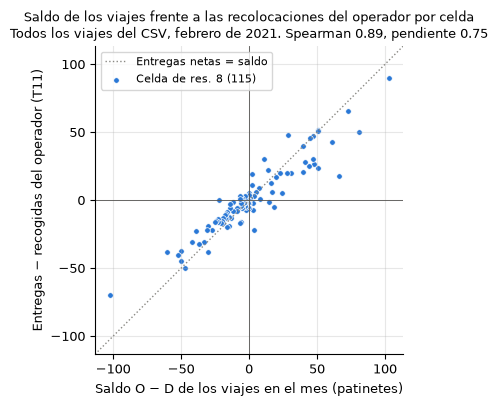

,h3,origenes,destinos,saldo,recogidas,entregas,neto_entregas,diferencia
0,881e805089fffff,1206,1103,103,161,251,90,-13
1,881e8051dbfffff,437,356,81,77,127,50,-31
2,881e8052a5fffff,772,699,73,110,176,66,-7
3,881e805189fffff,422,356,66,73,91,18,-48
4,881e8050c1fffff,858,797,61,137,180,43,-18


In [6]:
# Mismo universo que T11: todos los viajes del CSV en el mes completo. Si el número de
# patinetes de cada celda no crece ni decrece en el mes, las entregas netas del operador
# (entregas − recogidas) igualan el saldo O − D de los viajes.
operador = pd.read_csv(TABLAS / "T11_celdas_res8.csv").rename(columns={"h3_res8": "h3"})
o_m, d_m = extremos(todos, PARAMETROS["res_mapas"])
cols = ["origenes", "destinos", "saldo", "recogidas", "entregas", "neto_entregas"]
frente = saldo(o_m, d_m, ["h3"])[["h3", "origenes", "destinos", "saldo"]].merge(
    operador[["h3", "recogidas", "entregas", "neto_entregas"]], on="h3", how="outer").fillna(0)
frente[cols] = frente[cols].astype("int64")
frente["diferencia"] = frente["neto_entregas"] - frente["saldo"]
frente = frente.sort_values(["saldo", "h3"], ascending=[False, True], ignore_index=True)
guardar_tabla(frente, "T14_saldo_frente_operador")

rho = spearmanr(frente["saldo"], frente["neto_entregas"]).statistic
pendiente, ordenada = np.polyfit(frente["saldo"], frente["neto_entregas"], 1)
compensado = 100 * (1 - frente["diferencia"].abs().sum() / frente["saldo"].abs().sum())
indicadores.update({
    "operador_spearman_saldo_neto_entregas": round(float(rho), 3),
    "operador_pendiente_neto_entregas_sobre_saldo": round(float(pendiente), 3),
    "operador_ordenada": round(float(ordenada), 2),
    "operador_pct_saldo_compensado": round(float(compensado), 1),
})

fig, eje = plt.subplots(figsize=(6.5, 4.0))
lim = 1.1 * max(frente["saldo"].abs().max(), frente["neto_entregas"].abs().max())
eje.plot([-lim, lim], [-lim, lim], color=GRIS_REF, lw=1, ls=":", label="Entregas netas = saldo")
eje.scatter(frente["saldo"], frente["neto_entregas"], s=16, color=COLOR_RECEPTORA, edgecolor="white", lw=0.5,
            label=f"Celda de res. {PARAMETROS['res_mapas']} ({len(frente)})")
eje.axhline(0, color="#52514e", lw=0.6)
eje.axvline(0, color="#52514e", lw=0.6)
eje.set_xlim(-lim, lim)
eje.set_ylim(-lim, lim)
eje.set_aspect("equal")
eje.set_xlabel("Saldo O − D de los viajes en el mes (patinetes)")
eje.set_ylabel("Entregas − recogidas del operador (T11)")
eje.legend(loc="upper left")
eje.set_title("Saldo de los viajes frente a las recolocaciones del operador por celda\n"
              f"Todos los viajes del CSV, febrero de 2021. Spearman {rho:.2f}, pendiente {pendiente:.2f}", fontsize=9)
guardar_figura(fig, TEMA, "T14_saldo_frente_operador")

exportar(FASE, "t14_operador", {"celdas": frente, "spearman": rho, "pendiente": pendiente,
                                "pct_compensado": compensado})
display(frente.head(5))

**Conclusiones.**

- Sí coinciden: Spearman de 0,89 y pendiente de 0,75 entre el saldo de los viajes y las entregas netas del operador en 115 celdas. Las recolocaciones compensan el 62,1 % del saldo.
- La celda en la que el operador entrega más es la principal emisora. **El piloto ya rebalanceaba**, aunque con recogidas de varios días (T11): el rebalanceo nocturno es parte del escenario base de la fase 1.

## 6. Tabla de indicadores

**Qué queremos ver.** Todos los indicadores de este notebook en una tabla.

**Por qué importa.** Es la tabla que citan `docs/conclusiones_eda.md` y la memoria.

In [7]:
resumen = tabla_indicadores(indicadores)
guardar_tabla(resumen, "T14_resumen")
exportar(FASE, "t14_resumen", resumen)
display(resumen)

,indicador,valor
0,viajes,16756
1,dias,21
2,llegadas_fuera_del_periodo,1
3,celdas_res8,111
4,celdas_incluidas,90
5,pct_extremos_en_celdas_incluidas,99.34
6,celdas_emisoras,42
7,celdas_receptoras,45
8,celdas_equilibradas,3
9,celdas_desequilibrio_signif_2sigma,14


## Decisiones

| Decisión | Valor |
|---|---|
| ¿Hace falta rebalanceo? | Sí: el saldo es estructural y el piloto ya lo compensaba |
| Orden de magnitud diario | Unos 100 patinetes/día en resolución 8 y unos 220 en resolución 9 (cota inferior) |
| Zonas con más anclajes (receptoras) | `881e8052adfffff`, entre San Pedro y Termini, y las de `T14_saldo_celdas.csv` con saldo negativo |
| Zonas con más stock inicial (emisoras) | `881e805089fffff`, al sureste del Coliseo, y varias del sur |
| Franjas del desequilibrio | Sobre todo la punta de mañana; se invierte por la tarde |

El detalle de cada decisión está en `docs/conclusiones_eda.md`.